# 04 — Segment-Specific Models (the core experiment)

**Goal:** Train a separate XGBoost model within each segment, then compare the aggregated
segment-specific performance against the unified baseline from notebook 03.

This directly answers **RQ2: do segment-specific classifiers outperform a unified model?**

**Outputs:**
- `../results/tables/segment_model_results.csv`
- `../results/tables/comparison_unified_vs_segment.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, recall_score
from imblearn.over_sampling import SMOTE
import xgboost as xgb

SEED = 42
np.random.seed(SEED)

# Reuse the EXACT same split as notebook 03
data = joblib.load('../data/processed/train_test.pkl')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
seg_train, seg_test = data['seg_train'], data['seg_test']
print('Loaded shared train/test split')


Loaded shared train/test split


## 1. Train one model per segment

For each segment we:
1. Take only that segment's training rows
2. Apply SMOTE *within* the segment (if it has enough minority samples)
3. Train an XGBoost model
4. Predict on that segment's test rows

We then stitch all segment predictions back together to get overall performance.

In [2]:
segment_preds = np.zeros(len(y_test))
segment_probas = np.zeros(len(y_test))
rows = []

for seg in sorted(seg_train.unique()):
    tr_mask = (seg_train == seg).values
    te_mask = (seg_test == seg).values
    X_tr, y_tr = X_train[tr_mask], y_train[tr_mask]
    X_te, y_te = X_test[te_mask], y_test[te_mask]

    # Skip if a segment is too small or single-class
    if y_tr.nunique() < 2 or len(y_te) < 5:
        rows.append([seg, len(y_tr), te_mask.sum(), y_tr.mean(), np.nan, np.nan])
        print(f'Segment {seg}: insufficient data')
        continue

    # SMOTE within the segment (guard against tiny minority classes)
    min_count = y_tr.value_counts().min()
    if min_count >= 6:
        sm = SMOTE(random_state=SEED, k_neighbors=min(5, min_count - 1))
        X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

    model = xgb.XGBClassifier(n_estimators=100, random_state=SEED,
                              eval_metric='logloss', verbosity=0)
    model.fit(X_tr, y_tr)
    segment_preds[te_mask] = model.predict(X_te)
    segment_probas[te_mask] = model.predict_proba(X_te)[:, 1]

    f1 = f1_score(y_te, segment_preds[te_mask], zero_division=0)
    try:
        auc = roc_auc_score(y_te, segment_probas[te_mask])
    except ValueError:
        auc = np.nan
    rows.append([seg, len(y_train[tr_mask]), te_mask.sum(),
                 y_train[tr_mask].mean(), f1, auc])

seg_results = pd.DataFrame(rows, columns=['Segment','n_train','n_test','ChurnRate','F1','AUC']).round(3)
print(seg_results)


   Segment  n_train  n_test  ChurnRate     F1    AUC
0        0     1738     418      0.159  0.235  0.700
1        1     1193     305      0.241  0.465  0.779
2        2     1928     478      0.465  0.645  0.706
3        3      766     206      0.046  0.222  0.663


## 2. Compare against the unified baseline

The key comparison of the whole project. We aggregate all segment predictions and compute
overall F1 and AUC, then place them next to the unified XGBoost result.

In [3]:
# Aggregate segment-specific performance
seg_acc = accuracy_score(y_test, segment_preds)
seg_f1  = f1_score(y_test, segment_preds)
seg_auc = roc_auc_score(y_test, segment_probas)

# Unified XGBoost result from notebook 03
unified = pd.read_csv('../results/tables/unified_results.csv', index_col=0)
uni_xgb = unified.loc['XGBoost']

comparison = pd.DataFrame({
    'Unified XGBoost':  [uni_xgb['Accuracy'], uni_xgb['F1'], uni_xgb['AUC-ROC']],
    'Segment-specific': [seg_acc, seg_f1, seg_auc],
}, index=['Accuracy', 'F1', 'AUC-ROC']).round(3)
print(comparison)


          Unified XGBoost  Segment-specific
Accuracy            0.766             0.763
F1                  0.556             0.548
AUC-ROC             0.812             0.805


## 3. Interpret honestly

Whether or not segment-specific wins overall, look at the per-segment table: some segments
(e.g. the high-churn one) may benefit a lot, while a very low-churn segment can be unstable
because it has too few churners to train on. **This nuance is exactly what earns marks in the
Discussion — report it honestly rather than hiding it.**

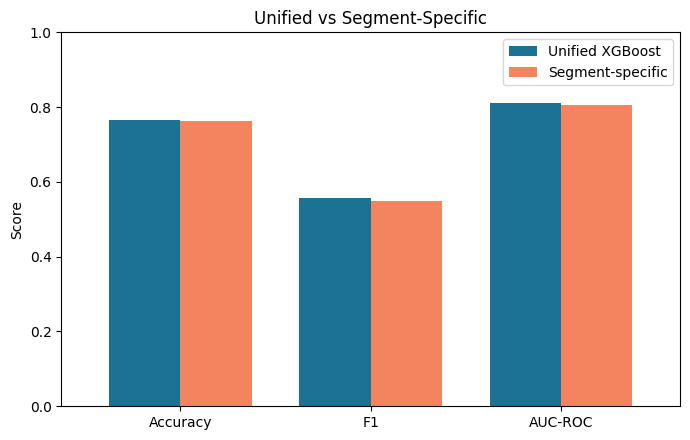

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
comparison.plot(kind='bar', ax=ax, color=['#1C7293', '#F4845F'], width=0.75)
ax.set_ylabel('Score'); ax.set_title('Unified vs Segment-Specific')
ax.set_ylim(0, 1); ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../results/figures/comparison.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. Save

In [5]:
seg_results.to_csv('../results/tables/segment_model_results.csv', index=False)
comparison.to_csv('../results/tables/comparison_unified_vs_segment.csv')
print('Saved: segment_model_results.csv, comparison_unified_vs_segment.csv, comparison.png')


Saved: segment_model_results.csv, comparison_unified_vs_segment.csv, comparison.png
